By: Suhas Makineni

Project 2 - NFL Redzone Effeciency Analysis



In [21]:
import pandas as pd
import numpy as np  
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats


Introduction:

The dataset that I am using for this project is the 2024 NFL play-by-play dataset, which keeps a record of every offensive play through the course of the season. Each row includes outcome of the play, yards gained, down, distance, field position, etc. The end goal of this project is to determine teams red zone effeciency, specifically how teams convert in the redzone. (How often redzone possesions result in touchdowns.)


In [22]:
# read csv file containing data
df = pd.read_csv('pbp-2024.csv')
df.head()


,GameId,GameDate,Quarter,Minute,Second,OffenseTeam,DefenseTeam,Down,ToGo,YardLine,...,IsTwoPointConversion,IsTwoPointConversionSuccessful,RushDirection,YardLineFixed,YardLineDirection,IsPenaltyAccepted,PenaltyTeam,IsNoPlay,PenaltyType,PenaltyYards
0,2024122907,2024-12-29,3,7,3,GB,MIN,1,10,16,...,0,0,CENTER,84,OPP,0,NaN,0,NaN,0
1,2024122907,2024-12-29,3,9,44,MIN,GB,0,0,0,...,0,0,NaN,100,OPP,0,NaN,0,NaN,0
2,2024122907,2024-12-29,3,9,44,MIN,GB,0,0,15,...,0,0,NaN,85,OPP,0,NaN,0,NaN,0
3,2024122907,2024-12-29,3,9,50,MIN,GB,1,10,18,...,0,0,NaN,82,OPP,0,NaN,0,NaN,0
4,2024122907,2024-12-29,3,15,0,MIN,GB,0,0,35,...,0,0,NaN,65,OPP,0,NaN,0,NaN,0


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53283 entries, 0 to 53282
Data columns (total 45 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   GameId                          53283 non-null  int64  
 1   GameDate                        53283 non-null  object 
 2   Quarter                         53283 non-null  int64  
 3   Minute                          53283 non-null  int64  
 4   Second                          53283 non-null  int64  
 5   OffenseTeam                     53283 non-null  object 
 6   DefenseTeam                     53283 non-null  object 
 7   Down                            53283 non-null  int64  
 8   ToGo                            53283 non-null  int64  
 9   YardLine                        53283 non-null  int64  
 10  Unnamed: 10                     0 non-null      float64
 11  SeriesFirstDown                 53283 non-null  int64  
 12  Unnamed: 12                     

In [24]:
df.shape

(53283, 45)

From the information from df.shape we are able to determine that there are 53,283 rows and 45 columns. For my goal to see how effecient teams are in the redzone a lot of these columns aren't necessarily useful. For example, special team plays, timeouts, and warnings are all unnecessary data. 

I mainly need the variables involving game context(quarters,offense/defence), field position, play situation (downs), and play results. 

Additionally, the rows that are timeouts, warnings, and etc aren't needed, essentially we just want the rows with rush and pass plays.

We can see using df.info that variables have different types including obj, int, and float. (After cleaning the dataset most variables with float were deleted) The columns data types make sense for football play by play data and won't need any type conversions. 

Also there are a few NULL values when looking at passtype (null if not passing play), rushdirection (null if not rushing play). A few columns as well are null columns that we need to get rid off.



In [25]:
# Loads Cleaned Dataset, remove null columns, keeps rush and pass plays, and keeps relevant variables

# drop empty columns 
empty_cols = [col for col in df.columns if df[col].isna().all()]
df = df.drop(columns=empty_cols)

# filters df to only RUSH or PASS plays
df = df[df["PlayType"].isin(["RUSH", "PASS"])]

# Keeping only the columns that are needed for analysis 
cols_needed = [
    "GameId", "GameDate", "Quarter", "Minute", "Second",
    "OffenseTeam", "DefenseTeam",
    "Down", "ToGo",
    "YardLine", "YardLineFixed", "YardLineDirection",
    "Yards", "IsTouchdown",
    "IsRush", "IsPass", "IsIncomplete",
    "PassType", "RushDirection",
    "IsPenalty", "PenaltyYards", "PenaltyType"
]

df = df[cols_needed]

df.head()




,GameId,GameDate,Quarter,Minute,Second,OffenseTeam,DefenseTeam,Down,ToGo,YardLine,...,Yards,IsTouchdown,IsRush,IsPass,IsIncomplete,PassType,RushDirection,IsPenalty,PenaltyYards,PenaltyType
0,2024122907,2024-12-29,3,7,3,GB,MIN,1,10,16,...,3,0,1,0,0,NaN,CENTER,0,0,NaN
3,2024122907,2024-12-29,3,9,50,MIN,GB,1,10,18,...,18,1,0,1,0,DEEP RIGHT,NaN,0,0,NaN
8,2025010401,2025-01-04,2,6,37,CIN,PIT,4,1,37,...,0,0,0,1,1,SHORT LEFT,NaN,0,0,NaN
9,2025010401,2025-01-04,2,7,20,CIN,PIT,3,6,42,...,5,0,0,1,0,SHORT LEFT,NaN,0,0,NaN
10,2025010401,2025-01-04,2,7,59,CIN,PIT,2,8,44,...,2,0,1,0,0,NaN,RIGHT GUARD,0,0,NaN


In [26]:
# Creates yardline_100 and red_zone variables

# Measures distance from opposing teams endzone
df["yardline_100"] = df["YardLineFixed"]

# Red zone is considered being inside opponents 20 yd line
df["red_zone"] = (df["yardline_100"] <= 20).astype(int)

# clean to int
df["td"] = df["IsTouchdown"].astype(int)

# shows that only null values in columns that they are ok being in
# print(df.isna().sum())

print("Cleaned dataset shape:", df.shape) # rows, cols
df.head()







Cleaned dataset shape: (33582, 25)


,GameId,GameDate,Quarter,Minute,Second,OffenseTeam,DefenseTeam,Down,ToGo,YardLine,...,IsPass,IsIncomplete,PassType,RushDirection,IsPenalty,PenaltyYards,PenaltyType,yardline_100,red_zone,td
0,2024122907,2024-12-29,3,7,3,GB,MIN,1,10,16,...,0,0,NaN,CENTER,0,0,NaN,84,0,0
3,2024122907,2024-12-29,3,9,50,MIN,GB,1,10,18,...,1,0,DEEP RIGHT,NaN,0,0,NaN,82,0,1
8,2025010401,2025-01-04,2,6,37,CIN,PIT,4,1,37,...,1,1,SHORT LEFT,NaN,0,0,NaN,63,0,0
9,2025010401,2025-01-04,2,7,20,CIN,PIT,3,6,42,...,1,0,SHORT LEFT,NaN,0,0,NaN,58,0,0
10,2025010401,2025-01-04,2,7,59,CIN,PIT,2,8,44,...,0,0,NaN,RIGHT GUARD,0,0,NaN,56,0,0


For my question specefically, the key variables I believe that will be the most important are yardline_100, down, togo, yards, and td. I created 3 variables td, yardline_100, and redzone. Redzone will be used later to easily filter plays in the redzone. td was made to track td's and yardline_100 is a useful variable telling us how far we are from a teams endzone

In [27]:

key_vars = ["Down", "ToGo", "yardline_100", "Yards", "td"]

df[key_vars].describe()

,Down,ToGo,yardline_100,Yards,td
count,33582.000000,33582.000000,33582.000000,33582.000000,33582.000000
mean,1.790334,8.474183,51.109076,6.122417,0.044458
std,0.830409,4.049187,24.539711,8.682509,0.206114
min,0.000000,0.000000,0.000000,-13.000000,0.000000
25%,1.000000,6.000000,31.000000,0.000000,0.000000
50%,2.000000,10.000000,47.000000,4.000000,0.000000
75%,2.000000,10.000000,70.000000,9.000000,0.000000
max,4.000000,40.000000,100.000000,102.000000,1.000000


This cell above gives good information about the entire dataset. We can see most plays happen on 1st or 2nd down with around 8 yards till the first and near midfield. Additionally, teams gain on average 6 yards per play and that on a given play a team has around a 4.5% chance to score. This informations all important to understand and will eventually be helpful to compare with the data we get from teams within the redzone. 



Some plays have very large gains and some have large losses of yards. Both of these could be seen as outliers but are part of the game and represent real football and will not be taken out.

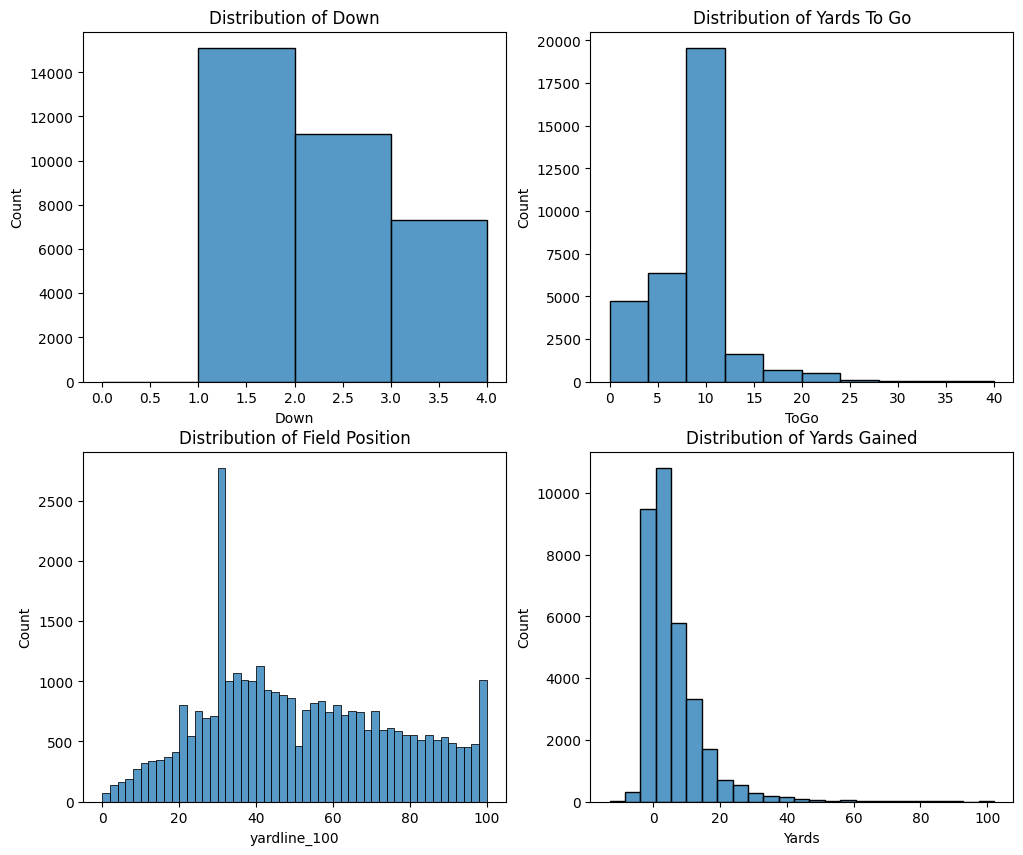

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10)) # creating grid for subplots

sns.histplot(df["Down"], bins=4, ax=axes[0, 0]) # plts dist of downs, 4 bins represent each down
axes[0, 0].set_title("Distribution of Down")

sns.histplot(df["ToGo"], bins=10, ax=axes[0, 1]) # plts dist of yards togo to first down, each bin represents a yard
axes[0, 1].set_title("Distribution of Yards To Go")

sns.histplot(df["yardline_100"], bins=50, ax=axes[1, 0]) # plts dist of field position, 0 means at your 0 yard line and 100 means at opponents endzone
axes[1, 0].set_title("Distribution of Field Position")

sns.histplot(df["Yards"], bins=25, ax=axes[1, 1]) # plts dist of yards gained on ecah play
axes[1, 1].set_title("Distribution of Yards Gained")

plt.show()

The distributions of the variables make sense with what we would expect from NFL data.

The distribution by down show that most plays occur on first or second down with less and less on third and fourth down. 

The yards to go distribution makes sense as well, most of the time teams have 10 yards to go according to our data. This aligns with football in the real world as every first down teams will have 10 yards to go. Also, the data points to the right of 10 represent penalties or sacks that result in a loss of yards. 

The field position data is concentrated around 30ish yards. When teams return a kickoff it is typically in the 25-30 range so this concentration makes sense. Besides that the distribution covers the full field which makes sense. 

The yards gained data is concentrated in the 0-5 range which makes sense with how many yards a team gets on a given play. 

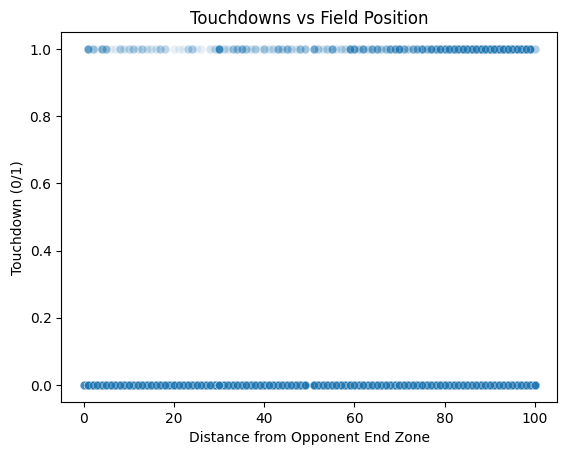

In [29]:
""" This scatter plot is not very useful as data is hard to make out. However, you can see that most of the points for Touchdown are concentrated in the 80-100 range
    telling us that touchdowns occur mostly in the endzone. """
sns.scatterplot(data=df, x="yardline_100", y="td", alpha=0.1)
plt.title("Touchdowns vs Field Position")
plt.xlabel("Distance from Opponent End Zone")
plt.ylabel("Touchdown (0/1)")
plt.show()

/var/folders/9f/d35pg8xn0sxf3g91gtx60r4m0000gn/T/ipykernel_19060/2879618138.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(bins)["td"].mean()


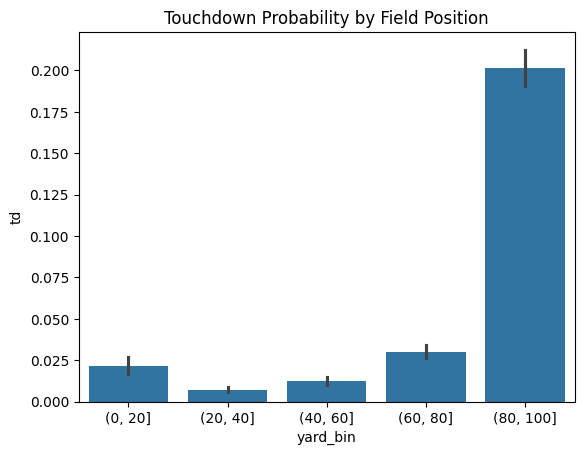

In [30]:
""" This histogram gives you a better picture of where teams score the most touchdowns. It looks to almost be a 20 percent chance when a team is in the redzone. """
bins = pd.cut(df["yardline_100"], bins=[0,20,40,60,80,100])
df.groupby(bins)["td"].mean()
df['yard_bin'] = pd.cut(df['yardline_100'], bins=[0,20,40,60,80,100])
order = df['yard_bin'].cat.categories

sns.barplot(x="yard_bin", y="td", data=df, order=order)
plt.title("Touchdown Probability by Field Position")
plt.show()

The bar plot shows that touchdown probability increases  when the offense is inside the opponent’s 20 yard line. Yard line ranges from 0 to 100, where values near 0 correspond to the offense being near their own 0 yard line and values near 100 correspond to teams being near the opposing teams endzone. 

As expected, touchdown probability is close to zero when the offense is far from scoring range and rises once the ball is past the opponent’s 20 yard line (the red zone) (80,100 range). This confirms that field position is a strong predictor of touchdown likelihood.

In [31]:
# Start looking at red zone data only
df_red = df[df["yardline_100"] >= 80] # Opposing teams 20 yard line
# df_red.head()
df_red.shape

df_red[["Down", "ToGo", "Yards", "td"]].describe()


,Down,ToGo,Yards,td
count,5546.000000,5546.000000,5546.000000,5546.000000
mean,1.879192,6.633069,3.820411,0.192932
std,0.862928,3.850364,5.891094,0.394636
min,1.000000,1.000000,-12.000000,0.000000
25%,1.000000,3.000000,0.000000,0.000000
50%,2.000000,7.000000,2.000000,0.000000
75%,3.000000,10.000000,6.000000,0.000000
max,4.000000,38.000000,102.000000,1.000000


In the red zone subset of the data most plays still occur on first and second down. Additionally most teams have 6.6 (0.5 more than full dataset) yards to go to the first down. On average teams are gaining 3.8 yards (significantly less) per play. And Td has now gone up to around a 19% chance from around 4.5%.

It's clear that teams score the more in the redzone compared to the overall data set. Now we are going to find out within the redzone where do teams score the most touchdown, on what downs, and what type of play. 

Hypothesis 1: Touchdown probability varies across field position inside the redzone

H0: Touchdown rates are equal across different fieldpositions in the redzone 

H1: Touchdown rates are not equal across different fieldposition in the redzone 

Hypothesis 2: Touchdown probability will differ by down inside the redzone 

H0: All downs have equal touchdown probability

H1: Some downs have a higher or lower likelihood of a touchdown

Hypothesis 3: Inside the redzone td probability depends on type of play

H0: Rushing and passing plays both have an equal probability of scoring

H1: Touchdown probability differs between rush and pass plays


/var/folders/9f/d35pg8xn0sxf3g91gtx60r4m0000gn/T/ipykernel_19060/3164591497.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  td_rates_rz = df_red.groupby("rz_bin")["td"].mean()


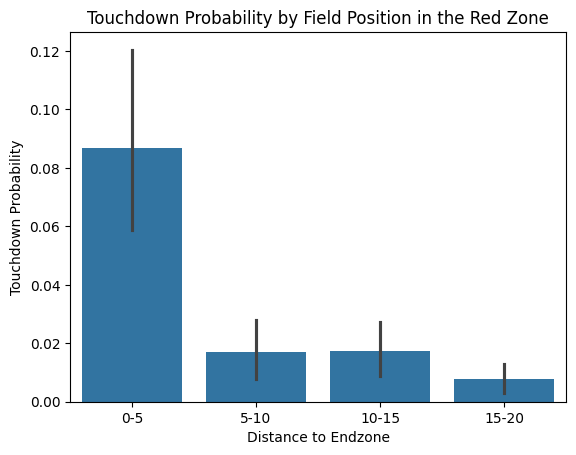

Chi-square = 86.6461, p-value = 0.0000


In [14]:
df_red = df[df["red_zone"] == 1].copy() #filters for red zone

df_red["rz_bin"] = pd.cut(
    df_red["yardline_100"],
    bins=[0, 5, 10, 15, 20],
    labels=["0-5", "5-10", "10-15", "15-20"]
) #bin field position inside red zone

td_rates_rz = df_red.groupby("rz_bin")["td"].mean()

sns.barplot(x="rz_bin", y="td", data=df_red, estimator=lambda x: x.mean())
plt.title("Touchdown Probability by Field Position in the Red Zone")
plt.xlabel("Distance to Endzone")
plt.ylabel("Touchdown Probability")
plt.show()

#df_red["yardline_100"].describe()
#df_red["rz_bin"].value_counts(dropna=False)

# Chi-square test for Hypothesis 1
contingency_pos = pd.crosstab(df_red["rz_bin"], df_red["td"])
chi2_pos, p_pos, dof_pos, exp_pos = stats.chi2_contingency(contingency_pos)


print(f"Chi-square = {chi2_pos:.4f}, p-value = {p_pos:.4f}")





The p-value is effectively 0 which is below 0.5 the significance threshold. Therefore we reject the null hypothesis that touchdown rates are equal across field positions inside the redzone. This matches the real world, teams are much more likely to score in the 0-5 yard range when they are closer to the endzone.  

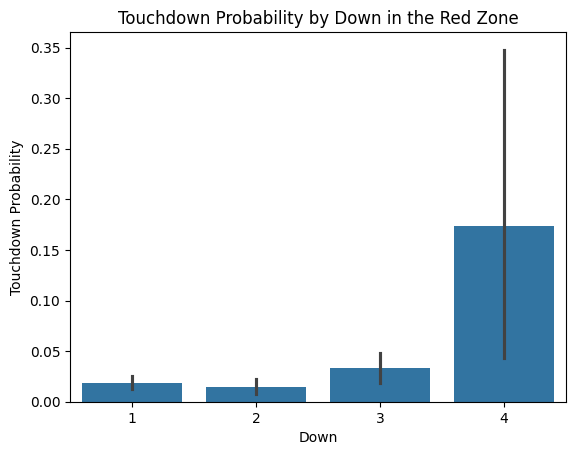

Chi-square = 32.1540, p-value = 0.000000


In [15]:
td_by_down = df_red.groupby("Down")["td"].mean()

sns.barplot(x="Down", y="td", data=df_red, estimator=lambda x: x.mean())
plt.title("Touchdown Probability by Down in the Red Zone")
plt.xlabel("Down")
plt.ylabel("Touchdown Probability")
plt.show()

contingency_down = pd.crosstab(df_red["Down"], df_red["td"])
chi2_down, p_down, dof_down, exp_down = stats.chi2_contingency(contingency_down)

print(f"Chi-square = {chi2_down:.4f}, p-value = {p_down:.6f}")



The results here were surprising and interesting. The chi square test gives us a low p value so we can reject the null hypothesis, meaning there is a strong relation between down and likelihood of a touchdown. I was expecting to see teams score mostly in the 1-3 down range, but the data shows teams score the most on 4th down. This most likely occurs because 4th down plays in the redzone are typically only attempted when the offense is really close to the goal line (within a few yards). This means that the down itself isn't really the main cause but the situation in which teams attempt to go for it on 4th downs. 

/var/folders/9f/d35pg8xn0sxf3g91gtx60r4m0000gn/T/ipykernel_19060/1862112688.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_red["play_type"] = df_red.apply(


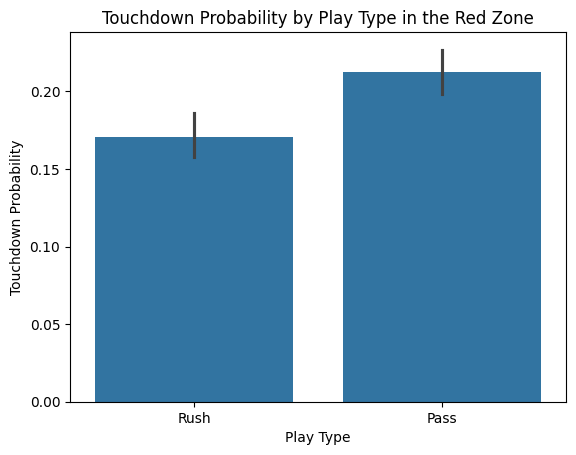

Chi-square = 15.1291, p-value = 0.000100


In [32]:
# creates new variable play type that labels each play as a pass or rush, ignores plays that are neither
df_red["play_type"] = df_red.apply(
    lambda row: "Pass" if row["IsPass"] == 1 else ("Rush" if row["IsRush"] == 1 else None),
    axis=1
)

df_red_play = df_red[df_red["play_type"].isin(["Rush", "Pass"])].copy() #filters to include rush and pass plays

td_by_play = df_red_play.groupby("play_type")["td"].mean()

sns.barplot(x="play_type", y="td", data=df_red_play, estimator=lambda x: x.mean())
plt.title("Touchdown Probability by Play Type in the Red Zone")
plt.xlabel("Play Type")
plt.ylabel("Touchdown Probability")
plt.show()

contingency_play = pd.crosstab(df_red_play["play_type"], df_red_play["td"])
chi2_play, p_play, dof_play, exp_play = stats.chi2_contingency(contingency_play)

print(f"Chi-square = {chi2_play:.4f}, p-value = {p_play:.6f}")

The p-value is much greater than 0.05 and we fail to reject the null hypothesis. Meaning there is no sifnificant difference between rush and passing plays resulting in a touchdown within the endzone. This was surprising to me after the second hypothesis results, I was expecting rushing plays to have a far higher probability because those are the most common plays run within in a yard. However, based on pure efficiency the data shows that both play types have a near equal chance of resulting in a touchdown. 

Overall conclusions from my hypothesis were that field position is the biggest indicator of touchdown probability. Down also matters but this is mainly because of where certain downs tend to occur (4th down near the goal line). Play type however does not significantly impact td likelihood in the redzone. 

The goal in the next section is to see if we can build a model to predict wheather a play will be a toucdown or not in the endzone. We are going to use the variables down, togo(yards to go), yardline_100 (distance to endzone), playtype, and penalties. 

In [17]:
from sklearn.model_selection import train_test_split

features = ["Down", "ToGo", "yardline_100", "IsRush", "IsPass", "IsPenalty"] #chosen variables
X = df_red[features]
y = df_red["td"]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42) #splits data into train and test sets

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
# Initialize and fit log reg model using training data. 
# This model also uses binary cross-entropy loss, the standard for the scikit-learns LogisticalRegression. 
# Logloss penalizes wrong probabilities heavy, which is what we want because tds are a rare event. 
logreg = LogisticRegression()
logreg.fit(X_train, y_train)

# Generates predictions on test set
log_pred = logreg.predict(X_test) # 0 or 1
log_probs = logreg.predict_proba(X_test)[:,1] # probabilities

log_acc = accuracy_score(y_test, log_pred) # measures how often model predicts correct class
log_auc = roc_auc_score(y_test, log_probs) # AUC (area under the roc curve) evaluates ability to distinguish between td and non td plays

print(f"Log Reg Accuracy: {log_acc}")
print(f"Log Reg AUC: {log_auc}")

Log Reg Accuracy: 0.9808306709265175
Log Reg AUC: 0.7462676438653637


To see whether I could predict the likelihood of a touchdown on a red zone play, I fit a logistic regression model using down, yards to go, field position, play type, and penalty information as predictors. The model achieved very high accuracy (0.988) and a moderately strong AUC score (0.746) on the test set.

The accuracy number is misleading because touchdowns in itself are rare events. This means the model could just predict no touchdown for every play and still have a accuracy close to 98%. This means accuracy isnt a reliable indicatior of the model.

The AUC score on the other hand is more informative. A score of 0.7463 indicates that the model can meaningfully distinguish between touchdowns and non-touchdown plays. This means the model correctly assigns a higher predicted probability 75% of the time when randomly comparing a touchdown and non touchdown. This means that the variables do have a clear positive relationship to tds. 

Next Im going to use a random forest model for predicting touchdowns. This type of model is used for more non linear relationships. These are extremely common in football. 

In [19]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, random_state=42) #initializes with 300 decision trees 
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test) #predicts class labels and proabilities
rf_probs = rf.predict_proba(X_test)[:,1]

#evaluates models performance again 
rf_acc = accuracy_score(y_test, rf_pred) # again accuracy can be misleading
rf_auc = roc_auc_score(y_test, rf_probs)

print(f"Random Forest Accuracy: {rf_acc}")
print(f"Random Forest AUC: {rf_auc}")

Random Forest Accuracy: 0.9712460063897763
Random Forest AUC: 0.7270629750271443


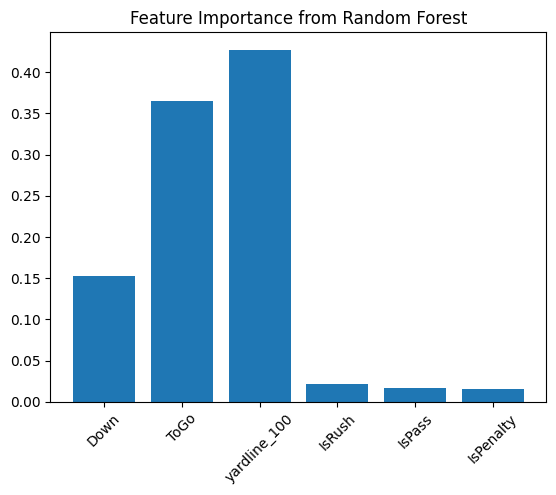

In [20]:
import numpy as np
import matplotlib.pyplot as plt
# shows which variables the random forest relied the most when predicting touchdowns. 
importances = rf.feature_importances_
plt.bar(features, importances)
plt.xticks(rotation=45)
plt.title("Feature Importance from Random Forest")
plt.show()

This Random Forest Classifier was trained using the same set of variables as the log regression model. The difference between the two is that Random Forests can represent non linear patterns. The accuracy of the model was 0.971 and the AUC 0.727.

For the same reason as the log regression the accuracy is high due to the reason touchdowns are rare events. Therefore, accuracy again is not meaningful

The AUC score of 0.727, indicates that the model has a moderate predective ability when comparing randomly selected touchdown plays against a non-touchdown play,the model correctly assigns a higher predicted touchdown probability approximately 73% of the time.


The Random Forest feature importance plot reveals how much each variable contributes to predicting touchdowns:

yardline_100 is the strongest predictor by a large margin. Down and ToGo also contribute meaningfully. IsRush, IsPass, and Ispenalty have very low importance. 

The logistic regression model outperformed the random forest AUC (0.746 vs 0.727). Given the variables and the target variable, logistic regression looks to be a more reliable  model for predicting touchdown probability in the red zone. Which leads me to think the relationship with the choosen variables there is more of a linear relationship than I orginally thought. 


